# Theme 3: Fine-Tuning Gemma, Starter Kit

This starter kit demonstrates the full fine-tuning workflow on **Gemma 4**, Google's open-weight model, using **Unsloth** on a free Colab GPU:

1. **Baseline:** measure how the plain Gemma model performs on a task.
2. **Fine-tune:** train a small set of additional weights (**LoRA**) on examples of the task.
3. **Compare:** measure the fine-tuned model on the same test set and compare the results.
4. **Application:** show both models side by side in a web application.

**Sample task:** IT support ticket triage. Given a support ticket, the model must reply with JSON containing the ticket's `category` and `priority`. The plain model does not know the required categories or format. The fine-tuned model learns them from about 180 examples. This makes the effect of fine-tuning easy to measure.

Your team will replace the sample task with the problem statement you selected (3A or 3B). Problem 3B uses images; see the section "Adapting for images (Problem 3B)" near the end of this notebook.

### Before you start: select a GPU
This notebook runs the Gemma model inside Google Colab and needs a GPU. Select **Runtime → Change runtime type → T4 GPU → Save**. The free T4 GPU is sufficient.

No API key is required. Gemma 4 is released under the Apache 2.0 licence and downloads without a Hugging Face account.

### How to use this notebook
- Run the cells **in order, from top to bottom**, the first time (select a cell and press **Shift + Enter**).
- Comments marked **STUDENT TODO** show the intended places to make changes.
- After changing a cell, re-run that cell and any cells below it that depend on it.
- If the notebook stops working as expected, select **Runtime → Restart session** and run all cells again from the top. The installation cell does not need to be repeated after a restart unless the runtime was disconnected.

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
import torch

print("CUDA available:", torch.cuda.is_available())

import unsloth
import transformers
import datasets
import trl
import gradio

print("Unsloth imported successfully")
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("TRL:", trl.__version__)
print("Gradio:", gradio.__version__)

CUDA available: True


ModuleNotFoundError: No module named 'unsloth'

## Step 0: Installation (run once)

In [8]:
from datasets import load_dataset

dataset = load_dataset("jsdnrs/ICDAR2019-SROIE")

print(dataset)

README.md:   0%|          | 0.00/14.3k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  319MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  191MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/626 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/361 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'key', 'image_size', 'entities', 'words', 'bboxes'],
        num_rows: 626
    })
    test: Dataset({
        features: ['image', 'key', 'image_size', 'entities', 'words', 'bboxes'],
        num_rows: 361
    })
})


Available fields: dict_keys(['image', 'key', 'image_size', 'entities', 'words', 'bboxes'])
Annotations: {'company': 'BOOK TA .K (TAMAN DAYA) SDN BHD', 'date': '25/12/2018', 'address': 'NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.', 'total': '9.00'}


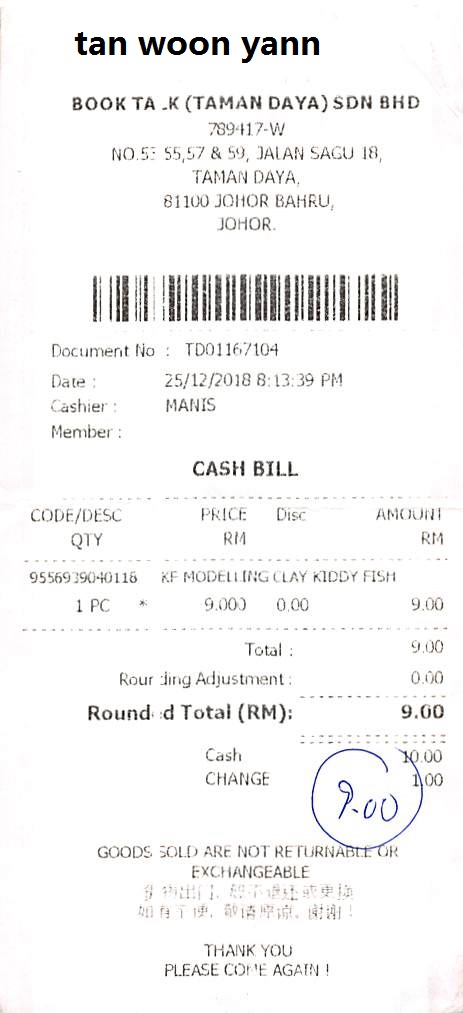

In [9]:
from IPython.display import display

sample = dataset["train"][0]

print("Available fields:", sample.keys())
print("Annotations:", sample["entities"])

display(sample["image"])

In [10]:
from unsloth import FastVisionModel

MODEL_NAME = "unsloth/gemma-4-E2B-it"

model, processor = FastVisionModel.from_pretrained(
    MODEL_NAME,
    load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
)

print("Loaded model:", MODEL_NAME)

==((====))==  Unsloth 2026.10.8: Fast Gemma4 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma4 won't work! Using float32.


Loading weights:   0%|          | 0/2011 [00:00<?, ?it/s]

Loaded model: unsloth/gemma-4-E2B-it


In [6]:
%%capture
# Installs Unsloth and compatible library versions (takes 2-4 minutes; output is hidden).
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth
else:
    !pip install sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer
    !pip install --no-deps unsloth_zoo bitsandbytes accelerate peft trl triton unsloth
    !unsloth install-kernels
    !pip install --no-deps --upgrade "torchao>=0.16.0"
!pip install --no-deps transformers==5.5.0 "tokenizers>=0.22.0,<=0.23.0"
!pip install "huggingface_hub>=1.5.0,<2.0"
!pip install --no-deps --upgrade timm
!pip install "gradio>=6,<7" pandas

In [5]:
import torch
if torch.cuda.is_available():
    print(f"GPU ready: {torch.cuda.get_device_name(0)}")
else:
    raise RuntimeError("No GPU found. Select Runtime → Change runtime type → T4 GPU, then run the notebook again from the top.")

GPU ready: Tesla T4


In [7]:
import torch
import unsloth

print("GPU ready:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Unsloth installed successfully")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
GPU ready: True
GPU: Tesla T4
Unsloth installed successfully


## Step 1: Load the plain Gemma model

In [ ]:
MAX_SEQ_LENGTH = 1024   # the maximum length of one training example (prompt + answer) in tokens

from unsloth import FastModel

# STUDENT TODO: the Gemma model to use.
#   "unsloth/gemma-4-E2B-it"  Gemma 4 E2B (about 2B effective parameters). Fits comfortably on a free T4. (default)
#   "unsloth/gemma-4-E4B-it"  Gemma 4 E4B (about 4B effective parameters). More capable, slower, uses more memory.
MODEL_NAME = "unsloth/gemma-4-E2B-it"

model, tokenizer = FastModel.from_pretrained(
    model_name = MODEL_NAME,
    dtype = None,              # selected automatically
    max_seq_length = MAX_SEQ_LENGTH,
    load_in_4bit = True,       # 4-bit quantisation reduces memory use
    full_finetuning = False,
)
print(f"Loaded {MODEL_NAME}")

In [11]:
import torch

INSTRUCTION = (
    "Extract the company, date, address and total from this receipt. "
    "Reply with JSON only, using exactly these four keys: "
    "company, date, address, total. Use strings for all values."
)

def generate_from_image(image, instruction=INSTRUCTION, max_new_tokens=256):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": instruction},
        ],
    }]

    input_text = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
    )

    inputs = processor(
        image.convert("RGB"),
        input_text,
        add_special_tokens=False,
        return_tensors="pt",
    ).to("cuda")

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            use_cache=True,
        )

    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    return processor.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()

print("Image-generation function ready.")

Image-generation function ready.


In [ ]:
def generate(user_text, system_text=None, max_new_tokens=256, temperature=0.0):
    """Sends one message to Gemma and returns its reply as text.
    temperature = 0.0 gives the same answer every time; higher values give more varied answers."""
    messages = []
    if system_text:
        messages.append({"role": "system", "content": [{"type": "text", "text": system_text}]})
    messages.append({"role": "user", "content": [{"type": "text", "text": user_text}]})

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt = True,
        tokenize = True,
        return_dict = True,
        return_tensors = "pt",
    ).to("cuda")

    sampling = {"do_sample": True, "temperature": temperature, "top_p": 0.95, "top_k": 64} if temperature > 0 else {"do_sample": False}
    outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, use_cache=True, **sampling)
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

print(generate("In one sentence, what is fine-tuning in machine learning?", max_new_tokens=80))

In [12]:
sample = dataset["test"][0]

print("Expected annotations:")
print(sample["entities"])

print("\nPlain Gemma prediction:")
prediction = generate_from_image(sample["image"])
print(prediction)

Expected annotations:
{'company': 'OJC MARKETING SDN BHD', 'date': '15/01/2019', 'address': 'NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, B1750 MASAI, JOHOR', 'total': '193.00'}

Plain Gemma prediction:
```json
{
  "company": "OJC MARKETING SDN BHD",
  "date": "15/01/2019",
  "address": "NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR",
  "total": "193.00"
}
```


In [1]:

import json

from unsloth import FastVisionModel

INSTRUCTION = (
    "Extract the company, date, address and total from this receipt. "
    "Reply with JSON only, using exactly these four keys: "
    "company, date, address, total. Use strings for all values."
)

def to_conversation(sample):
    target = json.dumps(
        {
            key: str(sample["entities"].get(key, ""))
            for key in ["company", "date", "address", "total"]
        },
        ensure_ascii=False,
    )

    return {
        "messages": [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": INSTRUCTION},
                    {"type": "image", "image": sample["image"]},
                ],
            },
            {
                "role": "assistant",
                "content": [
                    {"type": "text", "text": target},
                ],
            },
        ]
    }

train_conversations = [
    to_conversation(sample)
    for sample in dataset["train"]
]

print("Training examples:", len(train_conversations))
print("\nFirst training example:")
print(train_conversations[0]["messages"][1]["content"][0]["text"])


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


NameError: name 'dataset' is not defined

In [2]:

from datasets import load_dataset

dataset = load_dataset("jsdnrs/ICDAR2019-SROIE")

print(dataset)


DatasetDict({
    train: Dataset({
        features: ['image', 'key', 'image_size', 'entities', 'words', 'bboxes'],
        num_rows: 626
    })
    test: Dataset({
        features: ['image', 'key', 'image_size', 'entities', 'words', 'bboxes'],
        num_rows: 361
    })
})


In [3]:

import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


GPU available: True
GPU: Tesla T4


In [4]:

from unsloth import FastVisionModel

MODEL_NAME = "unsloth/gemma-4-E2B-it"

model, processor = FastVisionModel.from_pretrained(
    MODEL_NAME,
    load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
)

print("Model loaded successfully!")


==((====))==  Unsloth 2026.10.8: Fast Gemma4 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma4 won't work! Using float32.


Loading weights:   0%|          | 0/2011 [00:00<?, ?it/s]

Model loaded successfully!


In [ ]:

from datasets import load_dataset
import json

# Reload the dataset
dataset = load_dataset("jsdnrs/ICDAR2019-SROIE")

print("Dataset loaded:", len(dataset["train"]), "training receipts")

# Prepare training conversations
INSTRUCTION = (
    "Extract the company, date, address and total from this receipt. "
    "Reply with JSON only, using exactly these four keys: "
    "company, date, address, total. Use strings for all values."
)

def to_conversation(sample):
    target = json.dumps(
        {
            key: str(sample["entities"].get(key, ""))
            for key in ["company", "date", "address", "total"]
        },
        ensure_ascii=False,
    )

    return {
        "messages": [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": INSTRUCTION},
                    {"type": "image", "image": sample["image"]},
                ],
            },
            {
                "role": "assistant",
                "content": [{"type": "text", "text": target}],
            },
        ]
    }

train_conversations = [
    to_conversation(sample) for sample in dataset["train"]
]

print("Training examples:", len(train_conversations))
print("First target:")
print(train_conversations[0]["messages"][1]["content"][0]["text"])


Dataset loaded: 626 training receipts


In [4]:

from unsloth import FastVisionModel

print("FastVisionModel imported successfully!")


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
FastVisionModel imported successfully!


In [6]:

print("Model exists:", "model" in globals())
print("Dataset exists:", "dataset" in globals())
print("Training data exists:", "train_conversations" in globals())


Model exists: False
Dataset exists: False
Training data exists: False


In [7]:

from datasets import load_dataset
import json
import torch
from unsloth import FastVisionModel

dataset = load_dataset("jsdnrs/ICDAR2019-SROIE")

print("Training receipts:", len(dataset["train"]))
print("Test receipts:", len(dataset["test"]))
print("GPU available:", torch.cuda.is_available())



Training receipts: 626
Test receipts: 361
GPU available: True


In [8]:

from unsloth import FastVisionModel

MODEL_NAME = "unsloth/gemma-4-E2B-it"

model, processor = FastVisionModel.from_pretrained(
    MODEL_NAME,
    load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
)

print("Model loaded successfully!")


==((====))==  Unsloth 2026.10.8: Fast Gemma4 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma4 won't work! Using float32.


Loading weights:   0%|          | 0/2011 [00:00<?, ?it/s]

Model loaded successfully!


In [ ]:

from datasets import load_dataset
import json

# Load the dataset in this cell
dataset = load_dataset("jsdnrs/ICDAR2019-SROIE")

INSTRUCTION = (
    "Extract the company, date, address and total from this receipt. "
    "Reply with JSON only, using exactly these four keys: "
    "company, date, address, total. Use strings for all values."
)

def to_conversation(sample):
    target = json.dumps(
        {
            key: str(sample["entities"].get(key, ""))
            for key in ["company", "date", "address", "total"]
        },
        ensure_ascii=False,
    )

    return {
        "messages": [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": INSTRUCTION},
                    {"type": "image", "image": sample["image"]},
                ],
            },
            {
                "role": "assistant",
                "content": [{"type": "text", "text": target}],
            },
        ]
    }

train_conversations = [
    to_conversation(sample) for sample in dataset["train"]
]

print("Training examples:", len(train_conversations))
print("Example target:")
print(train_conversations[0]["messages"][1]["content"][0]["text"])


In [1]:

import os
import psutil
import torch

ram = psutil.virtual_memory()

print(f"System RAM total: {ram.total / 1024**3:.2f} GB")
print(f"System RAM available: {ram.available / 1024**3:.2f} GB")
print(f"GPU available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        f"GPU memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )


System RAM total: 12.67 GB
System RAM available: 8.85 GB
GPU available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [4]:

from datasets import load_dataset
import psutil
import torch

dataset = load_dataset("jsdnrs/ICDAR2019-SROIE")

print("Training receipts:", len(dataset["train"]))
print("Test receipts:", len(dataset["test"]))
print(f"Available RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB")
print("GPU:", torch.cuda.get_device_name(0))


Training receipts: 626
Test receipts: 361
Available RAM: 8.01 GB
GPU: Tesla T4


In [5]:

import json

INSTRUCTION = (
    "Extract the company, date, address and total from this receipt. "
    "Reply with JSON only, using exactly these four keys: "
    "company, date, address, total. Use strings for all values."
)

def to_conversation(sample):
    target = json.dumps(
        {
            key: str(sample["entities"].get(key, ""))
            for key in ["company", "date", "address", "total"]
        },
        ensure_ascii=False,
    )

    return {
        "messages": [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": INSTRUCTION},
                    {"type": "image", "image": sample["image"]},
                ],
            },
            {
                "role": "assistant",
                "content": [{"type": "text", "text": target}],
            },
        ]
    }

train_small = dataset["train"].select(range(100)).map(
    to_conversation,
    remove_columns=dataset["train"].column_names,
)

print("Small training subset:", len(train_small))
print("First target:")
print(train_small[0]["messages"][1]["content"][0]["text"])


Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Small training subset: 100
First target:
{"company": "BOOK TA .K (TAMAN DAYA) SDN BHD", "date": "25/12/2018", "address": "NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.", "total": "9.00"}


In [6]:

print("Model loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Training subset ready:", "train_small" in globals())

import torch
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )


Model loaded: False
Processor loaded: False
Training subset ready: True
GPU available: True
GPU memory allocated: 0.0 GB


In [7]:

from unsloth import FastVisionModel

MODEL_NAME = "unsloth/gemma-4-E2B-it"

model, processor = FastVisionModel.from_pretrained(
    MODEL_NAME,
    load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
)

print("Model loaded:", "model" in globals())
print("Processor loaded:", "processor" in globals())
print("Training subset ready:", "train_small" in globals())


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.8: Fast Gemma4 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma4 won't work! Using float32.


Loading weights:   0%|          | 0/2011 [00:00<?, ?it/s]

Model loaded: True
Processor loaded: True
Training subset ready: True


In [8]:

model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers=True,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=8,
    lora_alpha=8,
    lora_dropout=0,
    bias="none",
    random_state=3407,
)

FastVisionModel.for_training(model)

print("LoRA adapters configured successfully!")


LoRA adapters configured successfully!


In [9]:

from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig

trainer = SFTTrainer(
    model=model,
    train_dataset=train_small,
    processing_class=processor.tokenizer,
    data_collator=UnslothVisionDataCollator(model, processor),
    args=SFTConfig(
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        max_grad_norm=0.3,
        warmup_ratio=0.03,
        max_steps=20,
        learning_rate=1e-4,
        logging_steps=1,
        optim="adamw_8bit",
        weight_decay=0.001,
        lr_scheduler_type="cosine",
        seed=3407,
        output_dir="receiptai_outputs",
        report_to="none",
        remove_unused_columns=False,
        dataset_text_field="",
        dataset_kwargs={"skip_prepare_dataset": True},
        max_length=1024,
    ),
)

print("Trainer configured successfully!")


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Unsloth: Model does not have a default image size - using 512
Unsloth: Switching to float32 training since model cannot work with float16
Trainer configured successfully!


In [10]:

training_result = trainer.train()

print("Training finished!")
print(training_result.metrics)


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': 2}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 100 | Num Epochs = 1 | Total steps = 20
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 4 x 1) = 4
 "-____-"     Trainable parameters = 14,960,640 of 5,138,138,656 (0.29% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
1,2.936136
2,2.643688
3,2.800139
4,2.375520
5,2.245922
6,2.070671
7,2.224354
8,1.902414
9,2.043005
10,1.800340


Unsloth: Restored added_tokens_decoder metadata in receiptai_outputs/checkpoint-20/tokenizer_config.json.


Training finished!
{'train_runtime': 169.4082, 'train_samples_per_second': 0.472, 'train_steps_per_second': 0.118, 'total_flos': 449950334788032.0, 'train_loss': 1.8855712354183196, 'epoch': 0.8}


In [11]:

import os

SAVE_DIR = "/content/receiptai_lora"

model.save_pretrained(SAVE_DIR)
processor.save_pretrained(SAVE_DIR)

print("Adapter saved to:", SAVE_DIR)
print("Files:", os.listdir(SAVE_DIR))


Unsloth: Restored added_tokens_decoder metadata in /content/receiptai_lora/tokenizer_config.json.


Adapter saved to: /content/receiptai_lora
Files: ['tokenizer.json', 'tokenizer_config.json', 'README.md', 'processor_config.json', 'chat_template.jinja', 'adapter_model.safetensors', 'adapter_config.json']


In [13]:

import torch

FastVisionModel.for_inference(model)

sample = dataset["test"][0]

print("Expected annotations:")
print(sample["entities"])

messages = [{
    "role": "user",
    "content": [
        {"type": "image"},
        {"type": "text", "text": INSTRUCTION},
    ],
}]

input_text = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
)

inputs = processor(
    sample["image"].convert("RGB"),
    input_text,
    add_special_tokens=False,
    return_tensors="pt",
).to("cuda")

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=256,
        do_sample=False,
        use_cache=True,
    )

new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

prediction = processor.decode(
    new_tokens,
    skip_special_tokens=True,
).strip()

print("\nFine-tuned prediction:")
print(prediction)


Expected annotations:
{'company': 'OJC MARKETING SDN BHD', 'date': '15/01/2019', 'address': 'NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, B1750 MASAI, JOHOR', 'total': '193.00'}

Fine-tuned prediction:
{"company": "OJC MARKETING SDN BHD", "date": "15/01/2019", "address": "NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR", "total": "193.00"}


In [14]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/ReceiptAI"
os.makedirs(DRIVE_DIR, exist_ok=True)

shutil.copytree(
    "/content/receiptai_lora",
    f"{DRIVE_DIR}/receiptai_lora",
    dirs_exist_ok=True,
)

print("Adapter backed up to Google Drive:", f"{DRIVE_DIR}/receiptai_lora")


Mounted at /content/drive
Adapter backed up to Google Drive: /content/drive/MyDrive/ReceiptAI/receiptai_lora


In [15]:

import json
import re
import torch

def predict_receipt(image):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": INSTRUCTION},
        ],
    }]

    prompt = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
    )

    inputs = processor(
        image.convert("RGB"),
        prompt,
        add_special_tokens=False,
        return_tensors="pt",
    ).to("cuda")

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False,
            use_cache=True,
        )

    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return processor.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()

def parse_json(text):
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        match = re.search(r"\{.*\}", text, re.DOTALL)
        if match:
            try:
                return json.loads(match.group())
            except json.JSONDecodeError:
                pass
    return {}

def normalize(value):
    return re.sub(r"\s+", " ", str(value or "").strip()).casefold()

results = []

for i in range(20):
    sample = dataset["test"][i]
    prediction = parse_json(predict_receipt(sample["image"]))

    row = {"receipt": i}
    for field in ["company", "date", "address", "total"]:
        row[field] = normalize(prediction.get(field)) == normalize(
            sample["entities"].get(field)
        )
    results.append(row)

for field in ["company", "date", "address", "total"]:
    accuracy = sum(row[field] for row in results) / len(results)
    print(f"{field}: {accuracy:.0%} exact-match accuracy")

overall = sum(
    row[field]
    for row in results
    for field in ["company", "date", "address", "total"]
) / (len(results) * 4)

print(f"Overall field accuracy: {overall:.1%}")


company: 65% exact-match accuracy
date: 100% exact-match accuracy
address: 20% exact-match accuracy
total: 65% exact-match accuracy
Overall field accuracy: 62.5%


In [16]:

# Preserve the fine-tuned evaluation result
finetuned_accuracy = {
    "company": 0.65,
    "date": 1.00,
    "address": 0.20,
    "total": 0.65,
    "overall": 0.625,
}

# Clear the fine-tuned model from memory before loading the base model
import gc
import torch

del trainer
del model
del processor

gc.collect()
torch.cuda.empty_cache()

print("Fine-tuned model cleared from memory.")
print("GPU memory allocated:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")


Fine-tuned model cleared from memory.
GPU memory allocated: 5.16 GB


In [17]:

import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print("GPU memory allocated:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")

print("GPU memory reserved:", round(
    torch.cuda.memory_reserved() / 1024**3, 2
), "GB")


GPU memory allocated: 5.16 GB
GPU memory reserved: 8.31 GB


In [18]:

import psutil
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

ram = psutil.virtual_memory()

print(f"Available system RAM: {ram.available / 1024**3:.2f} GB")
print(f"GPU allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"GPU reserved: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")


Available system RAM: 5.33 GB
GPU allocated: 5.16 GB
GPU reserved: 8.31 GB


In [1]:

import torch
import psutil

ram = psutil.virtual_memory()

print(f"Available system RAM: {ram.available / 1024**3:.2f} GB")
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )


Available system RAM: 9.65 GB
GPU available: True
GPU: Tesla T4
GPU memory allocated: 0.0 GB


In [2]:

try:
    from unsloth import FastVisionModel
    print("Unsloth is ready!")
except ImportError as e:
    print("Unsloth needs installation.")
    print(e)


Unsloth needs installation.
No module named 'unsloth'


In [3]:

%pip install unsloth



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.4/29.4 MB 56.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 118.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 53.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 59.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 113.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 126.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 119.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 130.4 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [unsl

In [4]:

from unsloth import FastVisionModel
import torch

print("Unsloth import successful!")
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Unsloth import successful!
GPU available: True
GPU: Tesla T4


In [5]:
from google.colab import drive
drive.mount("/content/drive")

import os

adapter_path = "/content/drive/MyDrive/ReceiptAI/receiptai_lora"

print("Adapter folder exists:", os.path.isdir(adapter_path))
if os.path.isdir(adapter_path):
    print("Files:", os.listdir(adapter_path))

Mounted at /content/drive
Adapter folder exists: True
Files: ['README.md', 'adapter_model.safetensors', 'adapter_config.json', 'tokenizer_config.json', 'chat_template.jinja', 'tokenizer.json', 'processor_config.json']


In [6]:
from unsloth import FastVisionModel
from peft import PeftModel
import torch

base_model, processor = FastVisionModel.from_pretrained(
    "unsloth/gemma-4-E2B-it",
    load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
)

model = PeftModel.from_pretrained(
    base_model,
    "/content/drive/MyDrive/ReceiptAI/receiptai_lora",
)

FastVisionModel.for_inference(model)

print("ReceiptAI fine-tuned model loaded successfully!")

==((====))==  Unsloth 2026.10.8: Fast Gemma4 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma4 won't work! Using float32.


Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

ReceiptAI fine-tuned model loaded successfully!


In [7]:
from PIL import Image
import json

def predict_receipt(image):
    instruction = """Extract the following fields from this receipt:
    company, date, address, total.
    Return only valid JSON in this format:
    {"company": "", "date": "", "address": "", "total": ""}"""

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": instruction},
            ],
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False,
        )

    generated = outputs[0][inputs["input_ids"].shape[1]:]
    response = processor.decode(
        generated, skip_special_tokens=True
    ).strip()

    try:
        start = response.find("{")
        end = response.rfind("}") + 1
        return json.dumps(json.loads(response[start:end]), indent=2)
    except Exception:
        return response

print("ReceiptAI prediction function created successfully!")

ReceiptAI prediction function created successfully!


In [9]:
%pip install -q gradio

In [10]:
import gradio as gr
from PIL import Image

demo = gr.Interface(
    fn=predict_receipt,
    inputs=gr.Image(type="pil", label="Upload Receipt Image"),
    outputs=gr.Code(label="Extracted Receipt Details", language="json"),
    title="🧾 ReceiptAI",
    description=(
        "AI-powered receipt information extraction. "
        "Upload a receipt to extract company, date, address, and total."
    ),
    examples=None,
    flagging_mode="never",
)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://273f39e96105efab95.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Step 2: The task and the dataset

Each example is a pair: an **input** (the prompt the model receives) and the **output** the model should produce.

The sample dataset is generated in code. The **test set uses different ticket wording** from the training set, so the evaluation measures whether the model has learned the task rather than memorised the examples.

In [ ]:
import json, random

# STUDENT TODO: the instruction given with every input. Keep it identical for the baseline and the fine-tuned model.
INSTRUCTION = "Triage this IT support ticket."

CATEGORIES = ["network", "hardware", "software", "account_access", "printing"]
PLACES = ["the library", "Hostel Block C", "Lab 3", "the admin building", "the main auditorium", "Room B-204"]

TRAIN_TEMPLATES = {
    "network": ["The Wi-Fi in {place} keeps disconnecting every few minutes.",
                "I cannot connect to the campus network from {place}.",
                "Internet speed in {place} is extremely slow today.",
                "The ethernet port in {place} is not giving any connection."],
    "hardware": ["The projector in {place} does not turn on.",
                 "My laptop screen flickers when I connect it to the monitor in {place}.",
                 "The keyboard on the computer in {place} has several keys not working.",
                 "One of the desktop computers in {place} makes a loud noise and shuts down."],
    "software": ["Python is not installed on the lab computers in {place}.",
                 "The licence for MATLAB has expired on the machines in {place}.",
                 "Visual Studio Code crashes every time I open it on the computer in {place}.",
                 "The antivirus is blocking the course software on the PCs in {place}."],
    "account_access": ["I forgot my student portal password and cannot log in.",
                       "My college email account is locked after too many attempts.",
                       "I cannot sign in to the learning platform with my student ID.",
                       "Two-factor authentication codes are not reaching my phone."],
    "printing": ["The printer in {place} shows a paper jam error.",
                 "My print jobs are stuck in the queue for the printer in {place}.",
                 "The printer in {place} prints blank pages.",
                 "I cannot find the printer in {place} in the list of devices."],
}
TEST_TEMPLATES = {
    "network": ["No websites load when I am connected to the Wi-Fi in {place}.",
                "The network drops whenever more than ten people join in {place}."],
    "hardware": ["The mouse attached to the computer in {place} is not detected.",
                 "The speakers in {place} produce no sound during presentations."],
    "software": ["The required compiler gives an installation error on the computers in {place}.",
                 "The statistics package will not open on the systems in {place}."],
    "account_access": ["My password reset link says it has expired.",
                       "The library account shows my ID as invalid."],
    "printing": ["The printer in {place} has run out of toner.",
                 "Printing from my laptop to the printer in {place} fails with an error."],
}
TRAIN_URGENCY = {"high": ["This is urgent, my exam submission is due in an hour.", "The whole class is affected right now.", "Please fix this immediately."],
                 "medium": ["Please help when possible today.", "It is affecting my work.", "Could someone take a look?"],
                 "low": ["No rush, whenever you get a chance.", "It is a minor issue.", "This can wait until next week."]}
TEST_URGENCY = {"high": ["Our lab test starts in 20 minutes, please hurry."],
                "medium": ["I would appreciate help with this soon."],
                "low": ["Not important, just reporting it."]}


def make_examples(templates, urgency, seed):
    rng, examples = random.Random(seed), []
    for category, sentences in templates.items():
        for sentence in sentences:
            for priority, phrases in urgency.items():
                for phrase in phrases:
                    ticket = sentence.format(place=rng.choice(PLACES)) + " " + phrase
                    output = json.dumps({"category": category, "priority": priority})
                    examples.append({"input": f"{INSTRUCTION}\n\nTicket: {ticket}", "output": output})
    rng.shuffle(examples)
    return examples


# STUDENT TODO: replace these two lines with your own dataset (see "Using your own dataset" below).
train_examples = make_examples(TRAIN_TEMPLATES, TRAIN_URGENCY, seed=1)
test_examples = make_examples(TEST_TEMPLATES, TEST_URGENCY, seed=2)

print(f"{len(train_examples)} training examples, {len(test_examples)} test examples.\n")
print("Example input: ", train_examples[0]["input"])
print("Example output:", train_examples[0]["output"])

### Using your own dataset
Your dataset must become two lists of `{"input": ..., "output": ...}` pairs: one for training and one for testing. Keep the test examples out of the training set. Examples:

```python
# From a CSV file with columns "input" and "output" (upload it using the folder icon in the left sidebar):
import pandas as pd
rows = pd.read_csv("my_data.csv").to_dict("records")
random.Random(0).shuffle(rows)
test_examples, train_examples = rows[:30], rows[30:]

# Problem 3A: AI4Bharat IndicCMix (gated dataset).
# 1. Sign in at huggingface.co and accept the terms on https://huggingface.co/datasets/ai4bharat/IndicCMix
# 2. Create an access token at https://huggingface.co/settings/tokens
# 3. Add it in Colab Secrets (key icon, left sidebar) as HF_TOKEN, with Notebook access enabled.
from datasets import load_dataset
data = load_dataset("ai4bharat/IndicCMix", data_files="ka.parquet", split="train")  # STUDENT TODO: "ka.parquet" for Kannada or "hi.parquet" for Hindi
data = data.remove_columns(["audio"])   # the text columns are all that is needed
print(len(data), "examples")
LANGUAGE = "Kannada"  # STUDENT TODO: "Kannada" or "Hindi", matching the file above
pairs = [{"input": f"Rewrite this in casual romanized {LANGUAGE}, as people write in chat messages.\n\nText: {r['english']}",
          "output": r["romanized_casual"]} for r in data]
random.Random(0).shuffle(pairs)
test_examples, train_examples = pairs[:30], pairs[30:]
```

For Problem 3A, the outputs are text rather than JSON. Replace `score()` in the next step with a text-similarity measure, for example chrF:

```python
!pip install -q sacrebleu
import sacrebleu
def score(prediction, expected):
    return {"chrf": sacrebleu.sentence_chrf(prediction, [expected]).score}
```
Then change the metric names in `evaluate()` (`valid_json`, `category_correct`, `priority_correct`) to `chrf`.

For Problem 3B (images), see "Adapting for images (Problem 3B)" near the end of this notebook.

## Step 3: Baseline evaluation of the plain model

`score()` compares one model output with the expected output. `evaluate()` runs the model on every test example and reports the results.

In [ ]:
import re
import pandas as pd


def parse_json(text):
    """Extracts the first JSON object from a model reply, or returns None."""
    match = re.search(r"\{.*?\}", text, re.DOTALL)
    try:
        return json.loads(match.group(0)) if match else None
    except json.JSONDecodeError:
        return None


def score(prediction, expected):
    """STUDENT TODO: change this to measure what matters for your use case."""
    pred, gold = parse_json(prediction), json.loads(expected)
    if not isinstance(pred, dict):
        return {"valid_json": 0, "category_correct": 0, "priority_correct": 0}
    return {
        "valid_json": 1,
        "category_correct": int(str(pred.get("category", "")).lower() == gold["category"]),
        "priority_correct": int(str(pred.get("priority", "")).lower() == gold["priority"]),
    }


def evaluate(examples, label, generate_fn=None):
    generate_fn = generate_fn or generate
    rows = []
    for i, ex in enumerate(examples, start=1):
        prediction = generate_fn(ex["input"], max_new_tokens=64)
        rows.append({"input": ex["input"].split("\n\n", 1)[-1], "expected": ex["output"], label: prediction, **score(prediction, ex["output"])})
        print(f"\r{label}: {i}/{len(examples)} evaluated", end="")
    df = pd.DataFrame(rows)
    metrics = df[["valid_json", "category_correct", "priority_correct"]].mean().mul(100).round(1)
    print(f"\n{label} results (%):\n{metrics.to_string()}")
    return df, metrics


baseline_df, baseline_metrics = evaluate(test_examples, "plain_model")
baseline_df[["input", "expected", "plain_model"]].head(5)

## Step 4: Fine-tune with LoRA

**LoRA** (Low-Rank Adaptation) leaves the original model weights unchanged and trains a small set of additional weights. This makes fine-tuning possible on a free GPU in a few minutes.

In [ ]:
# STUDENT TODO: training settings.
LORA_RANK = 8          # size of the LoRA adapters; larger can learn more but may overfit
TRAIN_STEPS = 60       # number of training steps; increase for larger datasets
LEARNING_RATE = 2e-4

model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False,  # text only
    finetune_language_layers   = True,
    finetune_attention_modules = True,
    finetune_mlp_modules       = True,
    r = LORA_RANK,
    lora_alpha = LORA_RANK,
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

from unsloth.chat_templates import get_chat_template, train_on_responses_only
tokenizer = get_chat_template(tokenizer, chat_template = "gemma-4")

from datasets import Dataset
def to_text(example):
    conversation = [{"role": "user", "content": example["input"]},
                    {"role": "assistant", "content": example["output"]}]
    text = tokenizer.apply_chat_template(conversation, tokenize=False, add_generation_prompt=False)
    return {"text": text.removeprefix("<bos>")}

train_dataset = Dataset.from_list(train_examples).map(to_text)
print(train_dataset[0]["text"])

In [ ]:
from trl import SFTTrainer, SFTConfig

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_dataset,
    eval_dataset = None,
    args = SFTConfig(
        dataset_text_field = "text",
        per_device_train_batch_size = 1,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = TRAIN_STEPS,
        learning_rate = LEARNING_RATE,
        logging_steps = 5,
        optim = "adamw_8bit",
        weight_decay = 0.001,
        lr_scheduler_type = "linear",
        seed = 3407,
        report_to = "none",
    ),
)
trainer = train_on_responses_only(trainer)  # learn only from the expected outputs, not the prompts

trainer_stats = trainer.train()
print(f"Training finished in {trainer_stats.metrics['train_runtime'] / 60:.1f} minutes.")

## Step 5: Evaluate the fine-tuned model and compare

In [ ]:
finetuned_df, finetuned_metrics = evaluate(test_examples, "fine_tuned_model")

comparison = pd.DataFrame({"Plain Gemma (%)": baseline_metrics, "Fine-tuned Gemma (%)": finetuned_metrics})
comparison["Change (points)"] = comparison["Fine-tuned Gemma (%)"] - comparison["Plain Gemma (%)"]
print(comparison.to_string())

side_by_side = baseline_df[["input", "expected", "plain_model"]].copy()
side_by_side["fine_tuned_model"] = finetuned_df["fine_tuned_model"]
side_by_side.head(10)

## Step 6: Launch the comparison application
The application sends the same input to the plain model (by temporarily switching off the LoRA adapters) and to the fine-tuned model. Run this cell to open it below and create a **public link**.

In [ ]:
import gradio as gr

gr.close_all()  # closes any previous version of the application that is still running

APP_TITLE = "IT Support Ticket Triage"  # STUDENT TODO: rename for your use case
APP_DESCRIPTION = "Compare plain Gemma 4 with a version fine-tuned for this task."


def generate_plain(user_text, **kwargs):
    """Generates with the LoRA adapters switched off, which gives the plain model's behaviour."""
    try:
        with model.disable_adapter():
            return generate(user_text, **kwargs)
    except Exception as e:
        return f"(Plain model output unavailable: {e})"


def on_compare(text):
    if not text.strip():
        raise gr.Error("Enter an input first.")
    prompt = f"{INSTRUCTION}\n\nTicket: {text}"  # STUDENT TODO: build the prompt in the same way as your dataset
    return generate_plain(prompt, max_new_tokens=128), generate(prompt, max_new_tokens=128)


with gr.Blocks(title=APP_TITLE) as demo:
    gr.Markdown(f"# {APP_TITLE}\n{APP_DESCRIPTION}")
    input_box = gr.Textbox(label="Support ticket", lines=3, placeholder="Describe the problem...")
    compare_btn = gr.Button("Compare", variant="primary")
    with gr.Row():
        plain_out = gr.Textbox(label="Plain Gemma", lines=6)
        tuned_out = gr.Textbox(label="Fine-tuned Gemma", lines=6)
    gr.Examples(["The Wi-Fi in the cafeteria stopped working and I have an online quiz now.",
                 "The printer near the library entrance is printing faded text, not urgent."], inputs=input_box)
    compare_btn.click(on_compare, inputs=input_box, outputs=[plain_out, tuned_out])

demo.launch(share=True)

## Step 7 (optional): Save the fine-tuned adapters
The LoRA adapters are small (tens of megabytes). Save them before the Colab session ends if you want to reuse the model.

In [ ]:
model.save_pretrained("gemma_4_lora")
tokenizer.save_pretrained("gemma_4_lora")
!zip -qr gemma_4_lora.zip gemma_4_lora
print("Saved. Download gemma_4_lora.zip from the folder icon in the left sidebar.")
# To share on Hugging Face instead: model.push_to_hub("your-username/gemma_4_lora", token="YOUR_HF_TOKEN")

## Adapting for images (Problem 3B)
Fine-tuning on receipt images uses Unsloth's **vision** workflow. The steps are the same (baseline, fine-tune, compare, build), but the model loading, the data format and the trainer settings change. The code below is based on Unsloth's official Gemma 4 E2B vision notebook: https://colab.research.google.com/github/unslothai/notebooks/blob/main/nb/Gemma4_(E2B)-Vision.ipynb

**1. Load the model for images** (instead of Step 1):
```python
from unsloth import FastVisionModel
model, processor = FastVisionModel.from_pretrained(
    "unsloth/gemma-4-E2B-it",
    load_in_4bit = True,                     # keeps memory within a free T4
    use_gradient_checkpointing = "unsloth",
)
```

**2. Load the receipts dataset and format each example as a conversation with an image:**
```python
import json
from datasets import load_dataset
train_data = load_dataset("jsdnrs/ICDAR2019-SROIE", split="train")
test_data = load_dataset("jsdnrs/ICDAR2019-SROIE", split="test")

INSTRUCTION = "Extract the company, date, address and total from this receipt. Reply with JSON only."

def to_conversation(sample):
    target = json.dumps({k: sample["entities"][k] for k in ["company", "date", "address", "total"]})
    return {"messages": [
        {"role": "user", "content": [{"type": "text", "text": INSTRUCTION},
                                     {"type": "image", "image": sample["image"]}]},
        {"role": "assistant", "content": [{"type": "text", "text": target}]},
    ]}

train_conversations = [to_conversation(s) for s in train_data]
```

**3. Generate from an image** (use this for the baseline and for the fine-tuned evaluation):
```python
def generate_from_image(image, instruction=INSTRUCTION, max_new_tokens=256):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": instruction}]}]
    input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(image.convert("RGB"), input_text, add_special_tokens=False, return_tensors="pt").to("cuda")
    outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, use_cache=True, do_sample=False)
    return processor.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
```

**4. Add LoRA adapters and train** (instead of Step 4):
```python
model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers = True, finetune_language_layers = True,
    finetune_attention_modules = True, finetune_mlp_modules = True,
    r = 16, lora_alpha = 16, lora_dropout = 0, bias = "none", random_state = 3407,
)

from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig
trainer = SFTTrainer(
    model = model,
    train_dataset = train_conversations,
    processing_class = processor.tokenizer,
    data_collator = UnslothVisionDataCollator(model, processor),
    args = SFTConfig(
        per_device_train_batch_size = 1, gradient_accumulation_steps = 4,
        max_grad_norm = 0.3, warmup_ratio = 0.03, max_steps = 60,
        learning_rate = 2e-4, logging_steps = 5, optim = "adamw_8bit",
        weight_decay = 0.001, lr_scheduler_type = "cosine", seed = 3407,
        output_dir = "outputs", report_to = "none",
        # required for vision fine-tuning:
        remove_unused_columns = False, dataset_text_field = "",
        dataset_kwargs = {"skip_prepare_dataset": True}, max_length = 2048,
    ),
)
trainer.train()
```

**5. Score each field:** parse the JSON reply with `parse_json()` and compare each of the four fields with the annotation (for example ignoring case and extra spaces). Report the accuracy for each field for the plain and fine-tuned models. Use a subset of the 361 test receipts if GPU time is limited.

## Next steps
1. Re-read your selected problem statement (3A or 3B) in the Theme 3 document.
2. Prepare a training set and a separate test set.
3. Run the baseline evaluation, fine-tune, and compare. Record the settings used for every run.
4. Build the application around your fine-tuned model.
5. Attempt items from the **Good to have** section of the problem statement for additional credit.

**Note on fair comparison:** the plain model receives the same short instruction as the fine-tuned model. A stronger baseline gives the plain model a detailed prompt with the categories and format. Comparing against both baselines is listed under "Good to have".

## Troubleshooting

| Issue | Resolution |
|---|---|
| "No GPU found" | Select **Runtime → Change runtime type → T4 GPU**, then run all cells from the top. |
| `CUDA out of memory` | Select **Runtime → Restart session** and run the cells again. Reduce `MAX_SEQ_LENGTH` or `max_new_tokens`, or use the E2B model. |
| `NameError: name '...' is not defined` | A cell was skipped. Run all cells above in order. |
| The first answer is slow | Expected. The model is compiled on first use. Later answers are faster. |
| Installation errors | Select **Runtime → Disconnect and delete runtime**, then run the notebook again from the top. |
| GPU usage limit reached | Colab limits free GPU time per account. Continue with another team member's Google account. |
| The public link no longer works | Links expire when the Colab session disconnects. Re-run the launch cell to create a new link. |